# Examen práctico U5 — Ciencia de Datos

**Nota metodológica:** los ejercicios A y B utilizan datos sintéticos reproducibles (semilla 42). En el ejercicio A se simulan variables inspiradas en vivienda; en B se simulan cuatro perfiles de clientes. Los resultados no deben presentarse como estadísticas de una fuente real.

## Ejercicio A. Regresión lineal
Objetivo: predecir un valor continuo a partir de `MedInc`, dividir 80/20, calcular MSE, RMSE y R², e interpretar la recta.

Dimensiones: (5000, 4)
MedInc         float64
HouseAge       float64
AveRooms       float64
MedHouseVal    float64
dtype: object
Nulos por columna:
 MedInc         0
HouseAge       0
AveRooms       0
MedHouseVal    0
dtype: int64
Resumen:
             MedInc     HouseAge     AveRooms  MedHouseVal
count  5000.000000  5000.000000  5000.000000  5000.000000
mean      7.686379    26.430172     5.009690     3.058740
std       4.183642    14.684706     1.718222     1.369737
min       0.507522     1.016035     2.000079     0.150000
25%       4.043918    13.679243     3.499159     1.971778
50%       7.633752    26.752117     5.030996     3.079796
75%      11.355588    38.858171     6.486543     4.279821
max      14.996597    51.998828     7.999684     5.000000
Pendiente: 0.3035
Intercepto: 0.7224
MSE: 0.2895 | RMSE: 0.5381 | R²: 0.8448


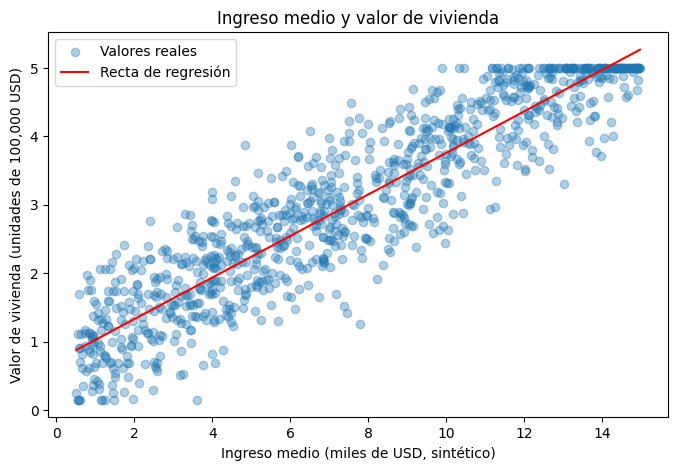

In [1]:
# EJERCICIO A: REGRESIÓN LINEAL
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Datos sintéticos reproducibles; la variable objetivo está en unidades de 100,000 USD.
rng = np.random.default_rng(42)
n = 5000
datos = pd.DataFrame({
    "MedInc": rng.uniform(0.5, 15, n),
    "HouseAge": rng.uniform(1, 52, n),
    "AveRooms": rng.uniform(2, 8, n)
})
ruido = rng.normal(0, 0.55, n)
datos["MedHouseVal"] = np.clip(
    0.35 + 0.32*datos["MedInc"] + 0.004*datos["HouseAge"]
    + 0.035*datos["AveRooms"] + ruido, 0.15, 5.0
)

# Inspección básica de dimensiones, tipos, nulos y valores extremos.
print("Dimensiones:", datos.shape)
print(datos.dtypes)
print("Nulos por columna:\n", datos.isna().sum())
print("Resumen:\n", datos.describe())

# Una sola característica facilita representar la recta solicitada.
X = datos[["MedInc"]]
y = datos["MedHouseVal"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

modelo = LinearRegression()
modelo.fit(X_train, y_train)
predicciones = modelo.predict(X_test)

mse = mean_squared_error(y_test, predicciones)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, predicciones)
print(f"Pendiente: {modelo.coef_[0]:.4f}")
print(f"Intercepto: {modelo.intercept_:.4f}")
print(f"MSE: {mse:.4f} | RMSE: {rmse:.4f} | R²: {r2:.4f}")

# Dispersión de observaciones reales y recta ajustada.
orden = np.argsort(X_test["MedInc"].to_numpy())
plt.figure(figsize=(8, 5))
plt.scatter(X_test["MedInc"], y_test, alpha=0.35, label="Valores reales")
plt.plot(X_test["MedInc"].to_numpy()[orden],
         predicciones[orden], color="red", label="Recta de regresión")
plt.title("Ingreso medio y valor de vivienda")
plt.xlabel("Ingreso medio (miles de USD, sintético)")
plt.ylabel("Valor de vivienda (unidades de 100,000 USD)")
plt.legend()
plt.show()


## Ejercicio B. Clustering K-Means
Objetivo: escalar ingreso y puntaje de gasto, comparar k=2..6 con inercia y silueta, elegir k=4, recuperar centroides en escala original y visualizar los grupos.

Nulos:
 Ingreso_anual_miles_USD    0
Puntaje_gasto              0
dtype: int64
Duplicados: 0
   k      Inercia  Silhouette
0  2  1084.325304    0.470361
1  3   542.275546    0.576276
2  4   167.273180    0.701416
3  5   147.421974    0.607797
4  6   133.234861    0.507703


Tamaño por clúster:
 Cluster
0    248
1    252
2    250
3    250
Name: count, dtype: int64
Centroides en escala original:
 [[74.88029342 79.68059177]
 [29.97833793 75.12795248]
 [24.99250424 19.81492479]
 [78.43671473 24.24679703]]


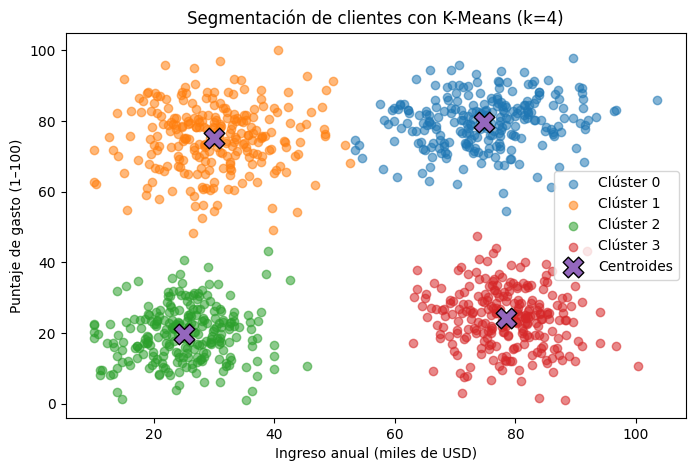

In [2]:
# EJERCICIO B: CLUSTERING K-MEANS
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Cuatro perfiles sintéticos de clientes; semilla fija para reproducibilidad.
rng = np.random.default_rng(42)
centros = np.array([[25, 20], [75, 80], [30, 75], [80, 25]], dtype=float)
desv = [[7, 8], [9, 7], [8, 9], [7, 8]]
partes = [rng.normal(loc=c, scale=s, size=(250, 2))
          for c, s in zip(centros, desv)]
clientes = pd.DataFrame(
    np.clip(np.vstack(partes), [10, 1], [120, 100]),
    columns=["Ingreso_anual_miles_USD", "Puntaje_gasto"]
)

# Revisión de calidad: nulos y duplicados.
print("Nulos:\n", clientes.isna().sum())
print("Duplicados:", clientes.duplicated().sum())

# Estandarización para que ambas variables tengan escala comparable.
escalador = StandardScaler()
Z = escalador.fit_transform(clientes)

# Método del codo y coeficiente de silueta para k entre 2 y 6.
resultados = []
for k in range(2, 7):
    modelo_k = KMeans(n_clusters=k, random_state=42, n_init=10)
    etiquetas_k = modelo_k.fit_predict(Z)
    resultados.append((k, modelo_k.inertia_,
                       silhouette_score(Z, etiquetas_k)))
print(pd.DataFrame(resultados,
      columns=["k", "Inercia", "Silhouette"]))

# k=4: la inercia cae notablemente hasta 4 y la silueta es máxima.
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
clientes["Cluster"] = kmeans.fit_predict(Z)
centroides = escalador.inverse_transform(kmeans.cluster_centers_)
print("Tamaño por clúster:\n", clientes["Cluster"].value_counts().sort_index())
print("Centroides en escala original:\n", centroides)

# Gráfico de grupos y centroides.
plt.figure(figsize=(8, 5))
for grupo in sorted(clientes["Cluster"].unique()):
    sub = clientes[clientes["Cluster"] == grupo]
    plt.scatter(sub.iloc[:, 0], sub.iloc[:, 1],
                alpha=0.55, label=f"Clúster {grupo}")
plt.scatter(centroides[:, 0], centroides[:, 1],
            marker="X", s=220, edgecolor="black", label="Centroides")
plt.title("Segmentación de clientes con K-Means (k=4)")
plt.xlabel("Ingreso anual (miles de USD)")
plt.ylabel("Puntaje de gasto (1–100)")
plt.legend()
plt.show()


## Interpretación y limitaciones
Los resultados corresponden a datos simulados. La regresión con una sola característica es útil para mostrar la recta, pero omite variables importantes. K-Means descubre perfiles geométricos y no etiquetas verdaderas; los grupos deben validarse con datos reales y contexto de negocio.